In [15]:
#for achiving normal distribution 
import pandas as pd 
import numpy as np 
import scipy.stats as stats

import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [16]:
df = sns.load_dataset('titanic')

In [17]:
df = df[['age', 'fare', 'survived']]

In [18]:
df.head()

,age,fare,survived
0,22.0,7.2500,0
1,38.0,71.2833,1
2,26.0,7.9250,1
3,35.0,53.1000,1
4,35.0,8.0500,0


In [19]:
df['age'] = df['age'].fillna(df['age'].mean())

In [20]:
df

,age,fare,survived
0,22.000000,7.2500,0
1,38.000000,71.2833,1
2,26.000000,7.9250,1
3,35.000000,53.1000,1
4,35.000000,8.0500,0
...,...,...,...
886,27.000000,13.0000,0
887,19.000000,30.0000,1
888,29.699118,23.4500,0
889,26.000000,30.0000,1


In [26]:
x = df.iloc[:,0:2]
y = df.iloc[:,2]

In [32]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

C:\Users\dgajj\AppData\Local\Temp\ipykernel_37184\1721657694.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['age'])


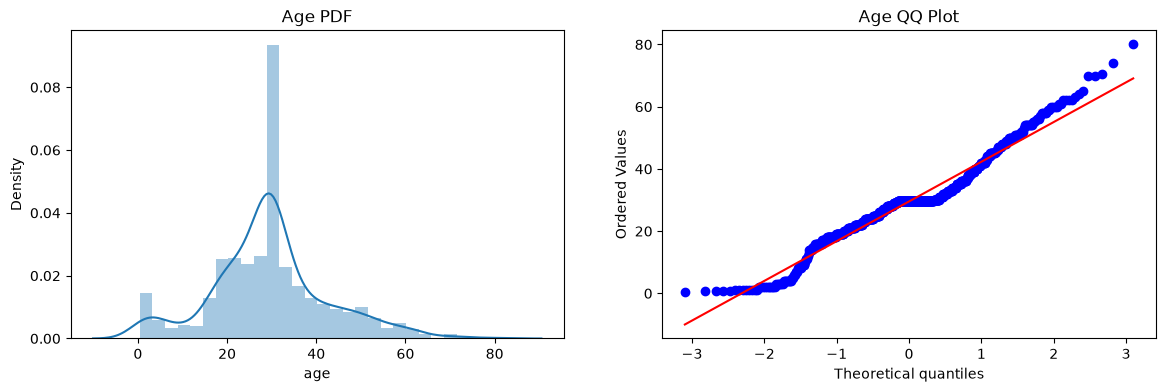

In [35]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.distplot(x_train['age'])
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(x_train['age'], dist="norm", plot=plt)
plt.title('Age QQ Plot')

plt.show()

C:\Users\dgajj\AppData\Local\Temp\ipykernel_37184\1262383534.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['fare'])


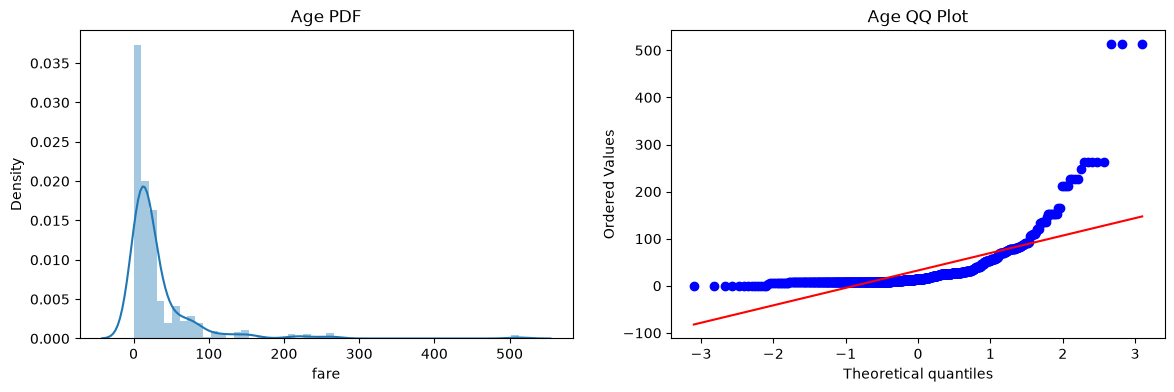

In [37]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.distplot(x_train['fare'])
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(x_train['fare'], dist="norm", plot=plt)
plt.title('Age QQ Plot')

plt.show()

In [38]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [39]:
clf.fit(x_train,y_train)
clf2.fit(x_train,y_train)
    
y_pred = clf.predict(x_test)
y_pred1 = clf2.predict(x_test)
    
print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred1))

Accuracy LR 0.6480446927374302
Accuracy DT 0.6759776536312849


In [40]:
#for predicating values and seeing it 
trf = FunctionTransformer(func=np.log1p)

In [42]:
X_train_transformed = trf.fit_transform(x_train)
X_test_transformed = trf.transform(x_test)

In [43]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed,y_train)
clf2.fit(X_train_transformed,y_train)
    
y_pred = clf.predict(X_test_transformed)
y_pred1 = clf2.predict(X_test_transformed)
    
print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred1))

Accuracy LR 0.6815642458100558
Accuracy DT 0.6703910614525139


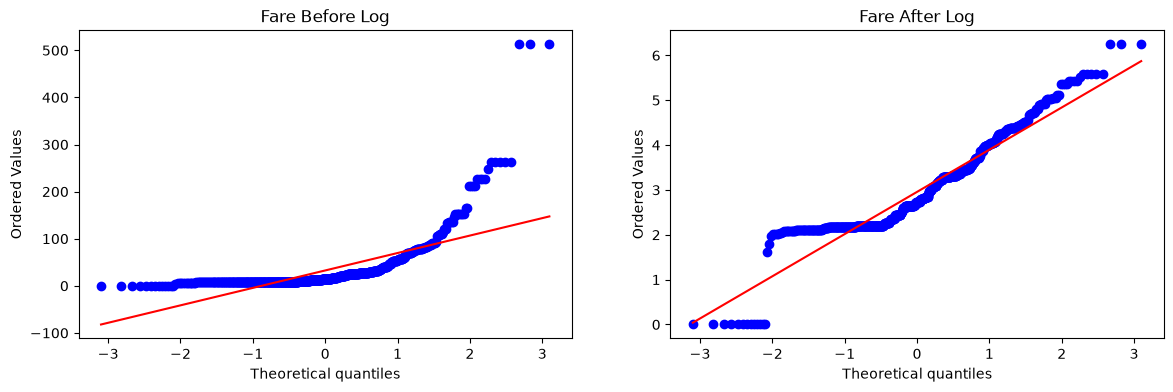

In [47]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(x_train['fare'], dist="norm", plot=plt)
plt.title('Fare Before Log')

plt.subplot(122)
stats.probplot(X_train_transformed['fare'], dist="norm", plot=plt)
plt.title('Fare After Log')

plt.show()